## Data Source
Kaggle "Diabetes" dataset (`diabetes.csv`) by Mohamadreza Momeni,
https://www.kaggle.com/datasets/imtkaggleteam/diabetes, accessed October 17, 2026.
See the README for the full description, license and download instructions.

In [1]:
import sys
sys.path.append("..")   # lets the notebook import from src/

from src.data_loader import load_data, inspect_data

raw = load_data()
print("Shape:", raw.shape)
raw.head()

Shape: (403, 19)


,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [2]:
print(raw.columns.tolist())
inspect_data(raw)

['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'location', 'age', 'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d', 'waist', 'hip', 'time.ppn']


,dtype,n_missing,pct_missing
id,int64,0,0.0
chol,float64,1,0.2
stab.glu,int64,0,0.0
hdl,float64,1,0.2
ratio,float64,1,0.2
glyhb,float64,13,3.2
location,str,0,0.0
age,int64,0,0.0
gender,str,0,0.0
height,float64,5,1.2


**Inspection summary.** The raw file has 403 rows and 19 columns. The variables include lab
values (cholesterol, HDL, glycosylated hemoglobin `glyhb`), demographics (age, gender,
location) and body measurements. Most columns have very few missing values, but `bp.2s` and
`bp.2d` are about 65% missing, so they will be dropped during cleaning. `glyhb`, our key
outcome measure, is missing in 13 rows (3.2%), and `frame` is missing in 12 rows (3.0%).

## Part 2: Modular Cleaning
The cleaning functions live in `src/cleaning.py`:
- `clean_columns`: standardizes column names and drops the mostly empty second blood pressure readings.
- `filter_records`: removes duplicates and rows missing `glyhb`, `age` or `weight`, and flags diabetes (`glyhb` of 6.5 or higher).
- `summarize_group`: returns count, mean, median and standard deviation of a variable by group.

In [3]:
from src.cleaning import clean_columns, filter_records, summarize_group

df = filter_records(clean_columns(raw))
print("Rows and columns:", raw.shape, "->", df.shape)
print(df["diabetes"].value_counts())
df.head()

Rows and columns: (403, 19) -> (389, 18)
diabetes
no     325
yes     64
Name: count, dtype: int64


,id,chol,stab_glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp_1s,bp_1d,waist,hip,time_ppn,diabetes
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,29.0,38.0,720.0,no
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,46.0,48.0,360.0,no
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,49.0,57.0,180.0,no
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,33.0,38.0,480.0,no
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,44.0,41.0,300.0,yes


In [4]:
summarize_group(df, "diabetes", "weight")

,count,mean,median,std
diabetes,,,,
no,325,174.57,170.0,40.09
yes,64,191.48,184.5,39.54


**Cleaning decisions.** I dropped `bp.2s` and `bp.2d` because about 65% of their values were
missing. I removed 14 rows missing `glyhb`, `age` or `weight` (13 of them lacked `glyhb`), and
kept the other columns as they are. Diabetes is defined as `glyhb` of 6.5 or higher, the cutoff
used on the Kaggle dataset page, which gives 64 patients with diabetes and 325 without.

Question 1

 How do glucose and age differ between people with and without diabetes?

In [5]:
print(summarize_group(df, "diabetes", "stab_glu"))
print(summarize_group(df, "diabetes", "age"))

          count    mean  median    std
diabetes                              
no          325   90.89    86.0  24.80
yes          64  188.81   183.0  79.32
          count   mean  median    std
diabetes                             
no          325  44.44    41.0  16.10
yes          64  58.44    59.5  12.94


**Question 1: glucose and age by diabetes status.** Patients with diabetes (glyhb of 6.5 or
higher) had a median stabilized glucose of 183 mg/dL, about twice the median of 86 mg/dL for
patients without diabetes. They were also older, with a median age of about 59.5 versus 41.
The glucose spread is much larger in the diabetes group (standard deviation 79 versus 25),
so blood sugar control varies widely among them. Substantively, high blood sugar and older
age both go along with diabetes in this sample, though this is an observational comparison and
does not show that age causes diabetes.

Question 2

What is related to glycosylated hemoglobin (glyhb)? Is prevalence different by gender or location?

In [7]:
import pandas as pd

In [8]:
print(df[["glyhb", "stab_glu", "age", "weight", "chol", "hdl"]].corr().round(2)["glyhb"])
print(pd.crosstab(df["gender"], df["diabetes"], normalize="index").round(3))
print(pd.crosstab(df["location"], df["diabetes"], normalize="index").round(3))

glyhb       1.00
stab_glu    0.74
age         0.34
weight      0.17
chol        0.27
hdl        -0.14
Name: glyhb, dtype: float64
diabetes     no    yes
gender                
female    0.842  0.158
male      0.826  0.174
diabetes       no    yes
location                
Buckingham  0.826  0.174
Louisa      0.844  0.156


**Question 2: what is associated with glyhb?** Stabilized glucose has the strongest
correlation with glycosylated hemoglobin (0.74), which makes sense because glyhb reflects
average blood sugar over the previous months. Age (0.34) and cholesterol (0.27) show moderate
positive associations, weight (0.17) a weak one, and HDL ("good" cholesterol) a weak negative
one (-0.14). Diabetes prevalence is similar across groups: 15.8% of women versus 17.4% of men,
and 17.4% in Buckingham versus 15.6% in Louisa. Gender and county therefore do not appear to
matter much here, while glucose and age do.

In [9]:
import matplotlib.pyplot as plt

colors = {"no": "#1f77b4", "yes": "#d62728"}   # blue = no diabetes, red = diabetes

Distribution plot

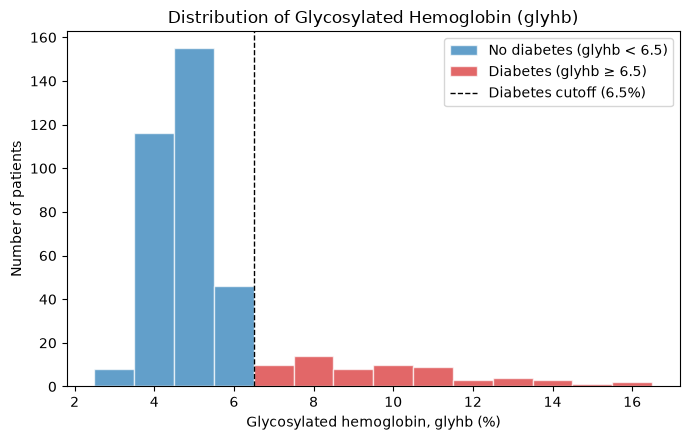

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, label in [("no", "No diabetes (glyhb < 6.5)"), ("yes", "Diabetes (glyhb ≥ 6.5)")]:
    ax.hist(df.loc[df["diabetes"] == g, "glyhb"], bins=[2.5 + i for i in range(15)],
            alpha=0.7, color=colors[g], edgecolor="white", label=label)
ax.axvline(6.5, color="black", linestyle="--", linewidth=1, label="Diabetes cutoff (6.5%)")
ax.set_title("Distribution of Glycosylated Hemoglobin (glyhb)")
ax.set_xlabel("Glycosylated hemoglobin, glyhb (%)")
ax.set_ylabel("Number of patients")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/fig1_glyhb_distribution.png", dpi=200)
plt.show()

**Figure 1.** Most patients have glyhb between 4% and 6%. The distribution is right-skewed, with a long tail of patients above the 6.5% diabetes cutoff reaching about 16%.

Comparison across groups

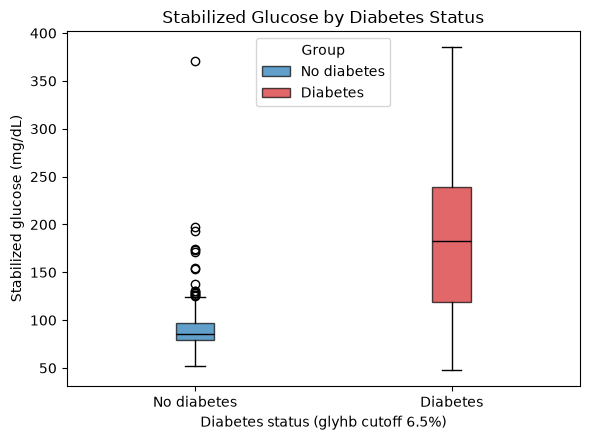

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
data = [df.loc[df["diabetes"] == g, "stab_glu"] for g in ["no", "yes"]]
bp = ax.boxplot(data, patch_artist=True, tick_labels=["No diabetes", "Diabetes"])
for patch, g in zip(bp["boxes"], ["no", "yes"]):
    patch.set_facecolor(colors[g])
    patch.set_alpha(0.7)
for med in bp["medians"]:
    med.set_color("black")
ax.set_title("Stabilized Glucose by Diabetes Status")
ax.set_xlabel("Diabetes status (glyhb cutoff 6.5%)")
ax.set_ylabel("Stabilized glucose (mg/dL)")
ax.legend(bp["boxes"], ["No diabetes", "Diabetes"], title="Group", loc="upper center")
fig.tight_layout()
fig.savefig("../figures/fig2_glucose_by_group.png", dpi=200)
plt.show()

**Figure 2.** Patients with diabetes have much higher stabilized glucose (median about 183 mg/dL) than patients without diabetes (median 86 mg/dL), and their glucose values are far more spread out.

Relationship plot

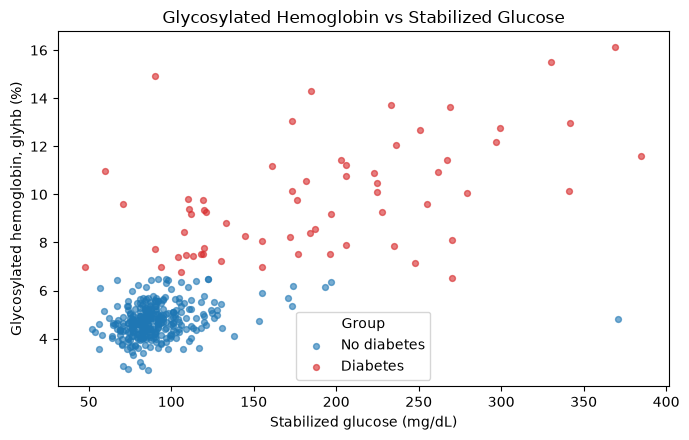

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, label in [("no", "No diabetes"), ("yes", "Diabetes")]:
    s = df[df["diabetes"] == g]
    ax.scatter(s["stab_glu"], s["glyhb"], alpha=0.6, s=18, color=colors[g], label=label)
ax.set_title("Glycosylated Hemoglobin vs Stabilized Glucose")
ax.set_xlabel("Stabilized glucose (mg/dL)")
ax.set_ylabel("Glycosylated hemoglobin, glyhb (%)")
ax.legend(title="Group")
fig.tight_layout()
fig.savefig("../figures/fig3_glyhb_vs_glucose.png", dpi=200)
plt.show()

**Figure 3.** Glyhb rises with stabilized glucose (correlation 0.74). Patients with diabetes cluster at higher glucose and glyhb, while those without cluster near 80–100 mg/dL and 4–6%.